In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
"""Predict a Continuous Target — Build a Linear Regression model to predict the target variable.
Then apply Ridge and Lasso regularization and compare coefficients.
Evaluate all three models using MAE, MSE, RMSE and R², and state which model generalizes best and why."""


'Predict a Continuous Target — Build a Linear Regression model to predict the target variable. \nThen apply Ridge and Lasso regularization and compare coefficients. \nEvaluate all three models using MAE, MSE, RMSE and R², and state which model generalizes best and why.'

In [3]:
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [4]:
df = pd.read_csv('/content/housing.csv')

In [5]:
df.head(10)

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
5,-122.25,37.85,52.0,919.0,213.0,413.0,193.0,4.0368,269700.0,NEAR BAY
6,-122.25,37.84,52.0,2535.0,489.0,1094.0,514.0,3.6591,299200.0,NEAR BAY
7,-122.25,37.84,52.0,3104.0,687.0,1157.0,647.0,3.1200,241400.0,NEAR BAY
8,-122.26,37.84,42.0,2555.0,665.0,1206.0,595.0,2.0804,226700.0,NEAR BAY
9,-122.25,37.84,52.0,3549.0,707.0,1551.0,714.0,3.6912,261100.0,NEAR BAY


In [6]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


<Axes: >

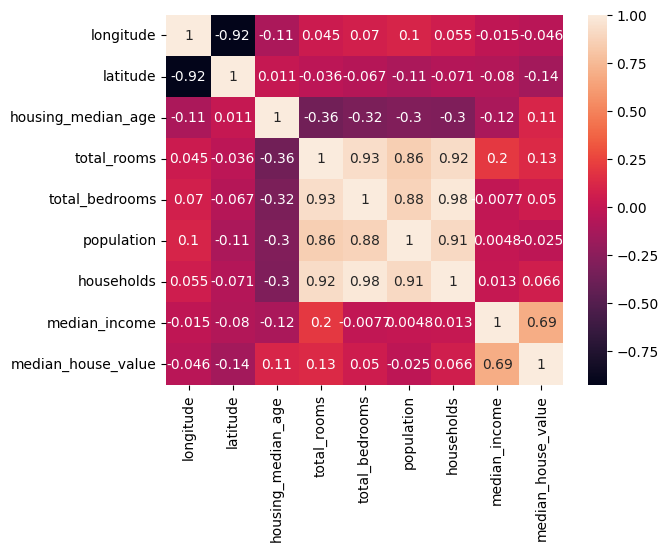

In [8]:
sns.heatmap(df.drop(columns=['ocean_proximity']).corr(),annot=True)

<Axes: ylabel='longitude'>

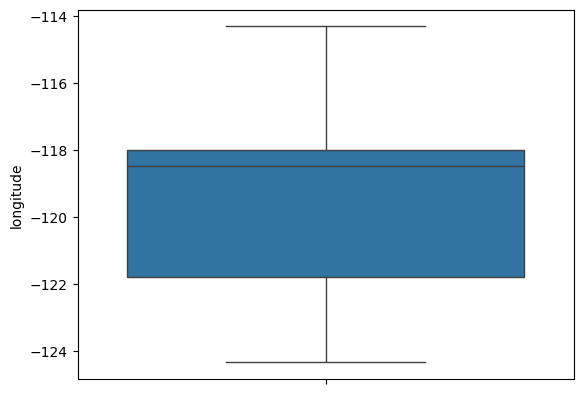

In [9]:
sns.boxplot(df['longitude'])

<Axes: ylabel='latitude'>

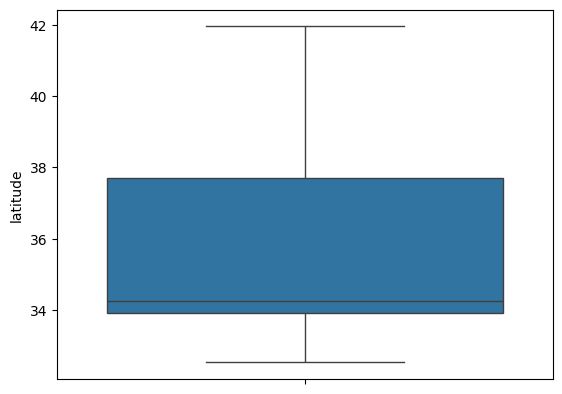

In [10]:
sns.boxplot(df['latitude'])

<Axes: ylabel='total_rooms'>

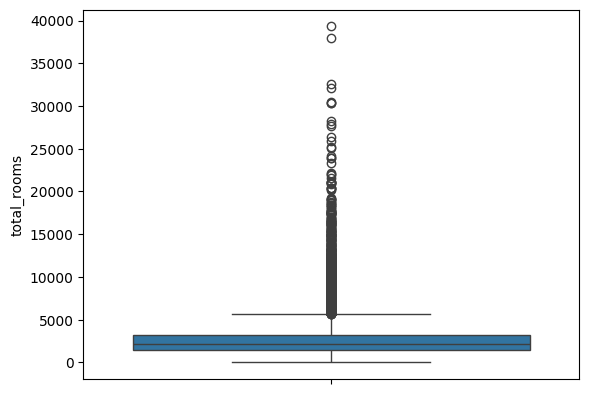

In [11]:
sns.boxplot(df['total_rooms'])

<Axes: ylabel='housing_median_age'>

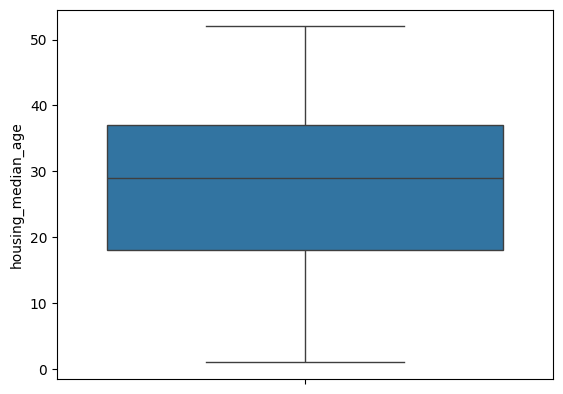

In [12]:
sns.boxplot(df['housing_median_age'])

<Axes: ylabel='total_bedrooms'>

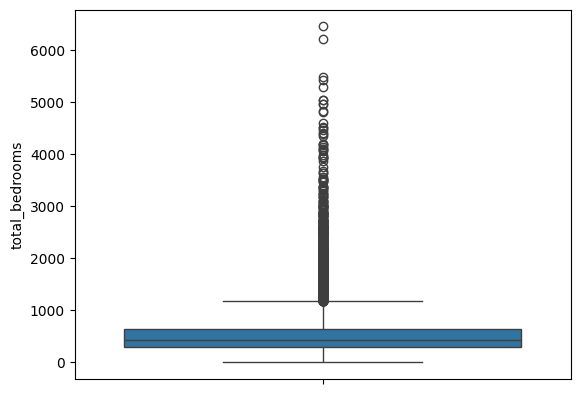

In [13]:
sns.boxplot(df['total_bedrooms'])

<Axes: ylabel='population'>

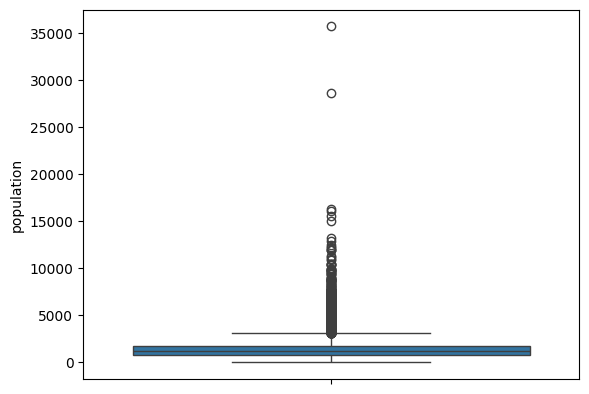

In [14]:
sns.boxplot(df['population'])

<Axes: ylabel='households'>

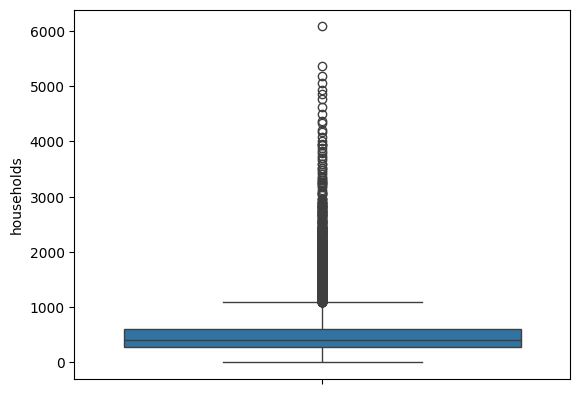

In [15]:
sns.boxplot(df['households'])

<Axes: ylabel='median_income'>

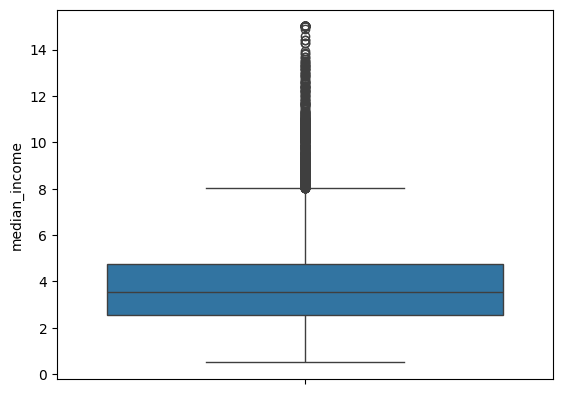

In [16]:
sns.boxplot(df['median_income'])

<Axes: ylabel='median_house_value'>

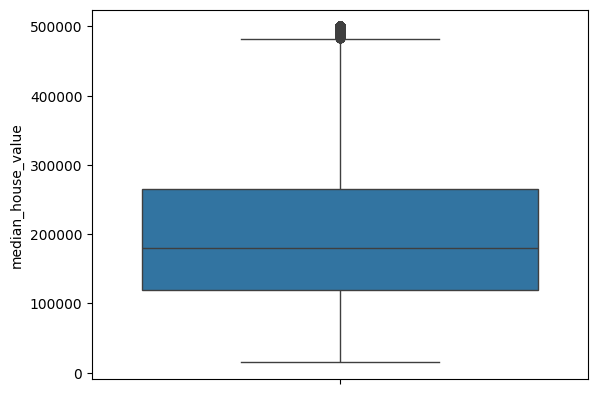

In [17]:
sns.boxplot(df['median_house_value'])

In [18]:
df['ocean_proximity'].unique()

array(['NEAR BAY', '<1H OCEAN', 'INLAND', 'NEAR OCEAN', 'ISLAND'],
      dtype=object)

In [19]:
score_map ={
    "INLAND" : 1,
    "<1H OCEAN" : 2,
    "NEAR BAY" : 3,
    "NEAR OCEAN" : 4,
    "ISLAND" : 5
}

df['ocean_proximity_labeled'] = df['ocean_proximity'].map(score_map)

In [20]:
df.duplicated().sum()

np.int64(0)

In [21]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [22]:
df['total_bedrooms'] = df['total_bedrooms'].fillna(df['total_bedrooms'].median())

In [23]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [24]:
# Feature Creation
df["rooms_per_household"] = df["total_rooms"] / df["households"]
df["bedrooms_per_room"] = df["total_bedrooms"] / df["total_rooms"]
df["population_per_household"] = df["population"] / df["households"]

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   longitude                 20640 non-null  float64
 1   latitude                  20640 non-null  float64
 2   housing_median_age        20640 non-null  float64
 3   total_rooms               20640 non-null  float64
 4   total_bedrooms            20640 non-null  float64
 5   population                20640 non-null  float64
 6   households                20640 non-null  float64
 7   median_income             20640 non-null  float64
 8   median_house_value        20640 non-null  float64
 9   ocean_proximity           20640 non-null  object 
 10  ocean_proximity_labeled   20640 non-null  int64  
 11  rooms_per_household       20640 non-null  float64
 12  bedrooms_per_room         20640 non-null  float64
 13  population_per_household  20640 non-null  float64
dtypes: flo

In [27]:
df1 = df.drop(columns =['total_rooms','households','total_bedrooms','population','ocean_proximity'])

In [28]:
df1.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   longitude                 20640 non-null  float64
 1   latitude                  20640 non-null  float64
 2   housing_median_age        20640 non-null  float64
 3   median_income             20640 non-null  float64
 4   median_house_value        20640 non-null  float64
 5   ocean_proximity_labeled   20640 non-null  int64  
 6   rooms_per_household       20640 non-null  float64
 7   bedrooms_per_room         20640 non-null  float64
 8   population_per_household  20640 non-null  float64
dtypes: float64(8), int64(1)
memory usage: 1.4 MB


In [29]:
# Train the model

X = df1.drop(columns=['median_house_value'])
Y = df1['median_house_value']

x_train,x_test,y_train,y_test = train_test_split(X,Y,test_size = 0.2)

In [30]:
# Linear Regression

lr = LinearRegression()
lr.fit(x_train,y_train)
pred_lr = lr.predict(x_test)

In [53]:
# Validation

lr.coef_

array([-36434.84846597, -35501.36483182,    883.13833738,  40767.59792522,
        10818.20845287,   2336.59239778, 207573.62026359,   -375.74650749])

In [32]:
lr.intercept_

np.float64(-3146102.248569778)

In [33]:
mean_squared_error(y_test,pred_lr)

5186910642.255611

In [34]:
root_mean_squared_error(y_test,pred_lr)

72020.20995703645

In [35]:
mean_absolute_error(y_test,pred_lr)

52335.30141055147

In [36]:
r2_score(y_test,pred_lr)

0.6177121934910812

In [38]:
# Lasso Regression

lasso = Lasso(alpha = 8)

lasso.fit(x_train,y_train)
pred_lasso= lasso.predict(x_test)

In [39]:
lasso.coef_

array([-36414.90949806, -35490.77933375,    883.77162799,  40717.96569028,
        10839.62677008,   2321.8811603 , 204706.32495162,   -375.44278012])

In [40]:
lasso.intercept_

np.float64(-3143273.5090390844)

In [41]:
mean_squared_error(y_test,pred_lasso)

5187308325.0237255

In [42]:
root_mean_squared_error(y_test,pred_lasso)

72022.97081503738

In [43]:
mean_absolute_error(y_test,pred_lasso)

52343.282138407

In [44]:
r2_score(y_test,pred_lasso)

0.6176828833132906

In [45]:
# Ridge Regression

ridge = Ridge(alpha = 10)

ridge.fit(x_train,y_train)
pred_ridge= ridge.predict(x_test)

In [46]:
ridge.coef_

array([-36570.32102027, -35736.84312645,    887.94438765,  40096.13100775,
        11017.3254083 ,   2188.14008411, 170574.26788438,   -372.6236442 ])

In [47]:
ridge.intercept_

np.float64(-3143152.523491119)

In [48]:
mean_squared_error(y_test,pred_ridge)

5196509906.609359

In [49]:
root_mean_squared_error(y_test,pred_ridge)

72086.82200381259

In [50]:
mean_absolute_error(y_test,pred_ridge)

52464.99397631413

In [51]:
r2_score(y_test,pred_ridge)

0.6170047045893063


### Evaluation Metrics Summary:
- **Linear Regression**:
  - MSE: ~5,186,910,642
  - RMSE: ~72,020
  - MAE: ~52,335
  - R²: ~0.61771

- **Lasso Regression (alpha=8)**:
  - MSE: ~5,187,308,325
  - RMSE: ~72,022
  - MAE: ~52,343
  - R²: ~0.61768

- **Ridge Regression (alpha=10)**:
  - MSE: ~5,196,509,906
  - RMSE: ~72,086
  - MAE: ~52,464
  - R²: ~0.61700

### Conclusion:
The **Linear Regression** model (closely tied with **Lasso Regression**) generalizes best on this specific test set splits, though the differences among all three models are extremely marginal.

### Why:
1. **Metrics Comparison**: The standard Linear Regression model achieved the lowest RMSE (~72,020) and highest R² (~0.61771) on the test split.
2. **Marginal Regularization Effect**: The regularization penalty in Ridge (alpha=10) and Lasso (alpha=8) slightly increased the errors, which indicates that the base OLS model is not overfitting to the training subset. This happens because the dataset contains a large number of samples relative to the feature space, meaning the model's variance is already low.